# CTPGesture_v1 — Complete VideoMamba P1 Results & 16-Frame Keyframe Explorer

**English-only Kaggle notebook.** Analyze the *saved Notebook Output* of the completed VideoMamba P1 evaluation; **no re-inference, source videos, checkpoint, or GPU required**. Start with **Add Input → Notebook Output** and attach the completed output for **CTPGesture_v1**. Use **Accelerator: None**.

### Contents
- Full **class-code legend** (e.g. `G06`, `B0A`, and `B0B` for IPN-Hand; `0`–`8` for CTPGesture) with original English class names and zero-based indices.
- Inventory of **all result files**, JSON metrics, and **every CSV** with searchable pagination.
- **All** Isolated and Continuous keyframe cases with Ground Truth, Prediction, correct/error status, temporal boundaries, confidence/tIoU, source, and full row metadata.
- Early Accuracy, Isolated confusion matrix, Continuous per-video metrics, other plots, saved notes, and cache inventory.

**Interpretation:** Continuous case-level errors may represent class confusion, missed gestures, fragmentation, boundary mismatch or false positives. The GT/Pred labels shown for unmatched events can be **midpoint contextual labels**, not a corresponding matched segment. GT-prefix Early Accuracy is **not** Online Early@10 or time-to-command.

**Performance:** The gallery indexes 100% of cases but displays 8 images per page by default. Bulk inline rendering is available as an explicit opt-in in the last cell; it may overload Kaggle/browser memory.

## 1. Connect completed Kaggle Output and display the full class-code reference

In [1]:
from pathlib import Path
import os, json, math, html, base64, warnings
import pandas as pd
import numpy as np
from IPython.display import display, HTML, Markdown, clear_output

DATASET_NAME = 'CTPGesture_v1'
EXPECTED_ROOT_TOKEN = 'p1_metric_audit'
CLASS_CODES = ['0', '1', '2', '3', '4', '5', '6', '7', '8']
CLASS_DESCRIPTIONS = ['No Gesture / Stand in attention', 'Stop', 'Forward', 'Left Turn', 'Left Turn Waiting', 'Right Turn', 'Lane Changing', 'Slow Down', 'Pull Over']
assert len(CLASS_CODES) == len(CLASS_DESCRIPTIONS)
CLASS_LABELS = [f'{code} — {name}' for code, name in zip(CLASS_CODES, CLASS_DESCRIPTIONS)]
CLASS_TABLE = pd.DataFrame({
    'Class index (0-based)': list(range(len(CLASS_CODES))),
    'Class code': CLASS_CODES,
    'Class name (English)': CLASS_DESCRIPTIONS,
})
# The attached Notebook Output is read-only. Set this if multiple runs are attached.
OUTPUT_INPUT_PATH = None             # e.g. '/kaggle/input/your-notebook-output'
INPUT_ROOT = Path('/kaggle/input')
SEARCH_ROOT = Path(OUTPUT_INPUT_PATH) if OUTPUT_INPUT_PATH else INPUT_ROOT
if not SEARCH_ROOT.is_dir():
    raise FileNotFoundError('Cannot locate Kaggle Input. Use Add Input > Notebook Output first.')

iso_files = sorted(SEARCH_ROOT.rglob('isolated_all_samples_index.csv'))
cont_files = sorted(SEARCH_ROOT.rglob('continuous_all_events_index.csv'))
iso_by_root = {p.parent.parent.resolve(): p for p in iso_files}
cont_by_root = {p.parent.parent.resolve(): p for p in cont_files}
matching_roots = sorted(
    [root for root in set(iso_by_root) & set(cont_by_root)
     if EXPECTED_ROOT_TOKEN.lower() in str(root).lower()], key=str)
print(f'Detected complete {DATASET_NAME} runs: {len(matching_roots)}')
for root in matching_roots: print('  -', root)
if len(matching_roots) != 1:
    raise RuntimeError('Attach exactly one completed Notebook Output with both image-index CSVs, '
                       'or set OUTPUT_INPUT_PATH to that specific Output directory.')
P1_ROOT = matching_roots[0]
ISO_INDEX_CSV = iso_by_root[P1_ROOT]
CONT_INDEX_CSV = cont_by_root[P1_ROOT]
OUTPUT_ROOT = P1_ROOT.parent
REPORT_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path('/tmp')
REPORT_DIR.mkdir(parents=True,exist_ok=True)
print('\nSelected input:',OUTPUT_ROOT)
print('Isolated index:', ISO_INDEX_CSV.relative_to(OUTPUT_ROOT))
print('Continuous index:', CONT_INDEX_CSV.relative_to(OUTPUT_ROOT))
print('\nCOMPLETE CLASS CODE REFERENCE')
display(CLASS_TABLE)
CLASS_TABLE.to_csv(REPORT_DIR/f'{DATASET_NAME}_class_reference.csv',index=False)
print('Note: CTPGesture uses numeric class codes 0–8; Gxx/Bxx codes refer to IPN-Hand, not CTPGesture.')

Detected complete CTPGesture_v1 runs: 1
  - /kaggle/input/notebooks/hoanganh94/videomamba-ctpgesture-p1-metrics-keyframes-python3/ctpgesture_videomamba_p1_evaluation/p1_metric_audit

Selected input: /kaggle/input/notebooks/hoanganh94/videomamba-ctpgesture-p1-metrics-keyframes-python3/ctpgesture_videomamba_p1_evaluation
Isolated index: p1_metric_audit/isolated_16frame/isolated_all_samples_index.csv
Continuous index: p1_metric_audit/continuous_16frame_timeline/continuous_all_events_index.csv

COMPLETE CLASS CODE REFERENCE


,Class index (0-based),Class code,Class name (English)
0,0,0,No Gesture / Stand in attention
1,1,1,Stop
2,2,2,Forward
3,3,3,Left Turn
4,4,4,Left Turn Waiting
5,5,5,Right Turn
6,6,6,Lane Changing
7,7,7,Slow Down
8,8,8,Pull Over


Note: CTPGesture uses numeric class codes 0–8; Gxx/Bxx codes refer to IPN-Hand, not CTPGesture.


## 2. Inventory every exported result file

In [2]:
# Complete inventory of relevant exported results; exclude source-code clones.
EXTENSIONS = {'.csv','.json','.jpg','.jpeg','.png','.pkl','.pickle','.parquet','.npz','.npy',
              '.txt','.log','.md','.html','.tsv','.yaml','.yml','.pdf','.svg'}
EXCLUDED_DIRS = {'VideoMamba','.git','__pycache__','.ipynb_checkpoints','site-packages','node_modules'}
FILE_TYPES = {'.csv':'CSV table','.json':'JSON metrics','.jpg':'JPEG keyframe','.jpeg':'JPEG keyframe',
              '.png':'PNG figure','.svg':'SVG figure','.pkl':'Raw inference cache','.pickle':'Raw inference cache',
              '.parquet':'Parquet data','.npz':'NumPy array','.npy':'NumPy array','.txt':'Text file',
              '.log':'Log file','.md':'Markdown file','.html':'HTML report','.tsv':'TSV table',
              '.yaml':'Configuration','.yml':'Configuration','.pdf':'PDF report'}
inventory_rows=[]
for folder, dirs, names in os.walk(OUTPUT_ROOT):
    dirs[:] = [name for name in dirs if name not in EXCLUDED_DIRS]
    for name in names:
        path=Path(folder)/name
        if path.suffix.lower() not in EXTENSIONS: continue
        try: size=path.stat().st_size
        except OSError: size=0
        inventory_rows.append({'Type':FILE_TYPES.get(path.suffix.lower(),'Other'),
            'Filename':path.name,'Relative path':path.relative_to(OUTPUT_ROOT).as_posix(),
            'Size (KiB)':round(size/1024,1),'Absolute path':str(path)})
INVENTORY = pd.DataFrame(inventory_rows,columns=['Type','Filename','Relative path','Size (KiB)','Absolute path'])
INVENTORY = INVENTORY.sort_values(['Type','Relative path']).reset_index(drop=True)
print(f'TOTAL RESULT FILES: {len(INVENTORY):,}')
if len(INVENTORY):
    display(INVENTORY.groupby('Type',as_index=False).agg(
        Files=('Filename','size'),Total_MiB=('Size (KiB)',lambda x:round(x.sum()/1024,2))))
    print('\nALL NON-KEYFRAME RESULT FILES')
    display(INVENTORY[INVENTORY['Type']!='JPEG keyframe'][['Type','Relative path','Size (KiB)']].reset_index(drop=True))
INVENTORY.drop(columns=['Absolute path']).to_csv(REPORT_DIR/f'{DATASET_NAME}_output_inventory.csv',index=False)
print('\nInventory saved:',REPORT_DIR/f'{DATASET_NAME}_output_inventory.csv')

TOTAL RESULT FILES: 2,744


,Type,Files,Total_MiB
0,CSV table,29,5.60
1,JPEG keyframe,2698,469.40
2,JSON metrics,5,0.00
3,Raw inference cache,12,1.91



ALL NON-KEYFRAME RESULT FILES


,Type,Relative path,Size (KiB)
0,CSV table,continuous_raw_per_video.csv,3.5
1,CSV table,ctpgesture_official_test_audit.csv,2.7
2,CSV table,ctpgesture_official_test_segments.csv,416.3
3,CSV table,isolated_classification_report.csv,0.9
4,CSV table,isolated_predictions.csv,501.3
5,CSV table,p1_metric_audit/continuous_16frame_timeline/co...,493.2
6,CSV table,p1_metric_audit/continuous_16frame_timeline/co...,0.1
7,CSV table,p1_metric_audit/continuous_16frame_timeline/se...,0.4
8,CSV table,p1_metric_audit/continuous_correct_cases.csv,117.1
9,CSV table,p1_metric_audit/continuous_error_cases.csv,226.1



Inventory saved: /kaggle/working/CTPGesture_v1_output_inventory.csv


## 3. Full JSON metrics and raw values

In [3]:
# Read every JSON result and preserve all original metric keys and values.
def flatten_json(value, prefix=''):
    if isinstance(value,dict):
        for key,item in value.items():
            yield from flatten_json(item, f'{prefix}.{key}' if prefix else str(key))
    elif isinstance(value,list):
        if len(value)<=50:
            for i,item in enumerate(value): yield from flatten_json(item,f'{prefix}[{i}]')
        else: yield prefix,value
    else: yield prefix,value

JSON_RESULTS={}
metric_rows=[]
for filename in INVENTORY.loc[INVENTORY['Type']=='JSON metrics','Absolute path']:
    path=Path(filename)
    try:
        with path.open('r',encoding='utf-8') as fh: content=json.load(fh)
        relative=path.relative_to(OUTPUT_ROOT).as_posix()
        JSON_RESULTS[relative]=content
        print('\n'+'='*78+'\nJSON FILE:',relative)
        display(HTML('<pre style="white-space:pre-wrap;overflow:auto;max-height:550px;border:1px solid #ddd;padding:10px">'
                     +html.escape(json.dumps(content,ensure_ascii=False,indent=2,default=str))+'</pre>'))
        for name,value in flatten_json(content):
            metric_rows.append({'Source JSON':relative,'Metric key':name,
                'Value':value if isinstance(value,(str,int,float,bool,type(None)))
                else json.dumps(value,ensure_ascii=False,default=str)})
    except Exception as e: print('Could not read JSON:',path.name,'|',e)
METRIC_INDEX=pd.DataFrame(metric_rows,columns=['Source JSON','Metric key','Value'])
print('\nFULL JSON METRIC INDEX')
if len(METRIC_INDEX): display(METRIC_INDEX)
else: print('No JSON metric files detected. The CSV browser below may contain the metrics.')


JSON FILE: p1_metric_audit/continuous_raw_segment_metrics_summary.json



JSON FILE: p1_metric_audit/early_auc.json



JSON FILE: p1_metric_audit/extra_continuous_metrics/detection_boundary_summary.json



JSON FILE: p1_metric_audit/extra_isolated_metrics/early_correctness_summary.json



JSON FILE: p1_metric_audit/isolated_calibration.json



FULL JSON METRIC INDEX


,Source JSON,Metric key,Value
0,p1_metric_audit/continuous_raw_segment_metrics...,videos,11
1,p1_metric_audit/continuous_raw_segment_metrics...,frames,67356
2,p1_metric_audit/continuous_raw_segment_metrics...,global_frame_accuracy,0.839836
3,p1_metric_audit/continuous_raw_segment_metrics...,global_macro_f1,0.806135
4,p1_metric_audit/continuous_raw_segment_metrics...,mean_edit_score_ms_tcn_pct,93.496805
...,...,...,...
57,p1_metric_audit/extra_isolated_metrics/early_c...,warning,Offline GT-defined isolated prefixes only; not...
58,p1_metric_audit/isolated_calibration.json,n,1728
59,p1_metric_audit/isolated_calibration.json,ece_15,0.005987
60,p1_metric_audit/isolated_calibration.json,multiclass_brier_sum,0.021505


## 4. Every CSV table: complete columns, previews and searchable pagination

In [4]:
# Every CSV is indexed. Browse any row without dropping data from the source.
CSV_PATHS={str(Path(p).relative_to(OUTPUT_ROOT)):Path(p) for p in
           INVENTORY.loc[INVENTORY['Type']=='CSV table','Absolute path']}
CSV_CACHE={}
def read_table(filename):
    if filename not in CSV_PATHS: raise KeyError(f'CSV not found: {filename}')
    if filename not in CSV_CACHE: CSV_CACHE[filename]=pd.read_csv(CSV_PATHS[filename],low_memory=False)
    return CSV_CACHE[filename]

def annotated_table(dataframe):
    out=dataframe.copy()
    for column in ['gt_idx','pred_idx','class_idx','gt_class','label']:
        if column in out.columns:
            ids=pd.to_numeric(out[column],errors='coerce')
            out[f'{column} / Class name']=ids.map(
                lambda i: CLASS_LABELS[int(i)] if pd.notna(i) and 0<=int(i)<len(CLASS_LABELS) else 'Unknown')
    if 'correct' in out.columns:
        out['Classification result']=out['correct'].map(
            lambda x:'Correct' if str(x).lower() in ('true','1','yes') else 'Incorrect')
    if 'status' in out.columns:
        out['Event result']=out['status'].map({'correct':'Correct','error':'Error'}).fillna('Other')
    return out

def show_csv(filename,page=1,rows_per_page=30,search=''):
    df=read_table(filename)
    if search:
        hit=df.astype(str).apply(lambda col:col.str.contains(search,case=False,regex=False,na=False)).any(axis=1)
        df=df[hit]
    rows_per_page=max(1,int(rows_per_page))
    num_pages=max(1,math.ceil(len(df)/rows_per_page))
    page=max(1,min(int(page),num_pages))
    first=(page-1)*rows_per_page
    print(f'CSV: {filename} | {len(df):,} rows × {len(df.columns)} columns | '
          f'Page {page}/{num_pages} | Rows {first+1 if len(df) else 0}–{min(first+rows_per_page,len(df))}')
    display(annotated_table(df.iloc[first:first+rows_per_page]))
    return num_pages

print('CSV FILES:',len(CSV_PATHS))
for filename in sorted(CSV_PATHS):
    try:
        table=read_table(filename)
        print('\n'+'─'*78+'\n',f'{filename}: {len(table):,} rows, {len(table.columns)} columns')
        print('Original columns:',', '.join(map(str,table.columns)))
        display(annotated_table(table.head(5)))
    except Exception as e: print('Unable to read CSV:',filename,'|',e)

try:
    import ipywidgets as widgets
    if CSV_PATHS:
        csv_choice=widgets.Dropdown(options=sorted(CSV_PATHS),description='CSV:',layout=widgets.Layout(width='98%'))
        csv_page=widgets.BoundedIntText(value=1,min=1,max=999999,description='Page:')
        csv_rows=widgets.Dropdown(options=[10,20,30,50,100,200],value=30,description='Rows:')
        csv_search=widgets.Text(description='Search:',placeholder='Search across all columns')
        csv_prev=widgets.Button(description='Previous page')
        csv_next=widgets.Button(description='Next page')
        csv_output=widgets.Output()
        def update_csv(*_):
            with csv_output:
                clear_output(wait=True)
                pages=show_csv(csv_choice.value,csv_page.value,csv_rows.value,csv_search.value)
            csv_prev.disabled=(csv_page.value<=1)
            csv_next.disabled=(csv_page.value>=pages)
        def reset_csv_page(change):
            if change['name']=='value':
                if csv_page.value!=1: csv_page.value=1
                else:update_csv()
        for w in [csv_choice,csv_rows,csv_search]:w.observe(reset_csv_page,names='value')
        csv_page.observe(lambda c:update_csv() if c['name']=='value' else None,names='value')
        csv_prev.on_click(lambda _:setattr(csv_page,'value',max(1,csv_page.value-1)))
        csv_next.on_click(lambda _:setattr(csv_page,'value',csv_page.value+1))
        display(widgets.VBox([csv_choice,widgets.HBox([csv_page,csv_rows,csv_prev,csv_next]),csv_search,csv_output]))
        update_csv()
except Exception as exc:
    print('Interactive CSV browser unavailable:',exc)
    print('Manual example: show_csv(next(iter(CSV_PATHS)),page=1,rows_per_page=30)')

CSV FILES: 29

──────────────────────────────────────────────────────────────────────────────
 continuous_raw_per_video.csv: 11 rows, 25 columns
Original columns: video_id, cache_source, frames, fps, duration_sec, windows, wall_sec, decode_preprocess_sec, model_forward_sec, wall_ms_per_window, model_ms_per_window, frame_accuracy, balanced_accuracy, macro_precision, macro_recall, macro_f1, weighted_f1, temporal_overlap, gesture_recall, pred_segments, gt_segments, link_operations, removal_changes, correct_frames, total_frames


,video_id,cache_source,frames,fps,duration_sec,windows,wall_sec,decode_preprocess_sec,model_forward_sec,wall_ms_per_window,...,macro_f1,weighted_f1,temporal_overlap,gesture_recall,pred_segments,gt_segments,link_operations,removal_changes,correct_frames,total_frames
0,2,fresh,10780,15.0,718.666667,1345,169.735556,88.089916,62.356743,126.197440,...,0.846244,0.901036,0.673491,0.950000,84,80,0,0,9701,10780
1,4,fresh,4291,15.0,286.066667,534,67.944298,35.467707,24.728225,127.236512,...,0.872820,0.892578,0.761775,0.980000,49,50,0,0,3827,4291
2,8,fresh,5781,15.0,385.400000,720,91.558346,47.989350,33.161955,127.164369,...,0.780885,0.819853,0.643465,1.000000,80,80,0,0,4722,5781
3,10,fresh,5252,15.0,350.133333,654,83.690756,43.833571,30.245486,127.967516,...,0.787235,0.831936,0.620349,0.958333,74,72,0,0,4357,5252
4,12,fresh,6274,15.0,418.266667,782,99.001331,51.707807,36.050022,126.600167,...,0.816285,0.856337,0.694758,0.931818,82,88,0,0,5402,6274



──────────────────────────────────────────────────────────────────────────────
 ctpgesture_official_test_audit.csv: 11 rows, 9 columns
Original columns: video_id, video_path, csv_path, video_frames, csv_labels, frame_diff, fps, width, height


,video_id,video_path,csv_path,video_frames,csv_labels,frame_diff,fps,width,height
0,2,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,10780,10780,0,15.0,1080,1080
1,4,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,4291,4291,0,15.0,1080,1080
2,8,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,5781,5781,0,15.0,1080,1080
3,10,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,5252,5252,0,15.0,1080,1080
4,12,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,6274,6274,0,15.0,1080,1080



──────────────────────────────────────────────────────────────────────────────
 ctpgesture_official_test_segments.csv: 1,728 rows, 8 columns
Original columns: sample_id, video_id, video_path, csv_path, label, t_start, t_end, duration_frames


...

,sample_id,video_id,t_start,t_end,duration_frames,gt_idx,gt_name,pred_idx,pred_name,confidence,...,prob_5,prob_6,prob_7,prob_8,original_t_end,prefix_end,observed_fraction,gt_idx / Class name,pred_idx / Class name,Classification result
0,002_seg0000,2,0,279,140,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.994529,...,0.000587,0.000944,0.001150,0.000427,279,139,0.5,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct
1,002_seg0001,2,280,315,18,1,Stop,1,Stop,0.901051,...,0.000380,0.000422,0.000357,0.096293,315,297,0.5,1 — Stop,1 — Stop,Correct
2,002_seg0002,2,316,369,27,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.993296,...,0.000088,0.000260,0.000294,0.000105,369,342,0.5,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct
3,002_seg0003,2,370,415,23,2,Forward,2,Forward,0.996703,...,0.002471,0.000179,0.000077,0.000106,415,392,0.5,2 — Forward,2 — Forward,Correct
4,002_seg0004,2,416,494,40,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.999328,...,0.000135,0.000087,0.000126,0.000017,494,455,0.5,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct



──────────────────────────────────────────────────────────────────────────────
 p1_metric_audit/isolated_prefix_075.csv: 1,728 rows, 23 columns
Original columns: sample_id, video_id, t_start, t_end, duration_frames, gt_idx, gt_name, pred_idx, pred_name, confidence, correct, prob_0, prob_1, prob_2, prob_3, prob_4, prob_5, prob_6, prob_7, prob_8, original_t_end, prefix_end, observed_fraction


,sample_id,video_id,t_start,t_end,duration_frames,gt_idx,gt_name,pred_idx,pred_name,confidence,...,prob_5,prob_6,prob_7,prob_8,original_t_end,prefix_end,observed_fraction,gt_idx / Class name,pred_idx / Class name,Classification result
0,002_seg0000,2,0,279,210,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.998097,...,0.000298,0.000239,0.000334,0.000077,279,209,0.75,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct
1,002_seg0001,2,280,315,27,1,Stop,1,Stop,0.679680,...,0.000522,0.000630,0.000509,0.316639,315,306,0.75,1 — Stop,1 — Stop,Correct
2,002_seg0002,2,316,369,41,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.996108,...,0.000081,0.000191,0.000214,0.000074,369,356,0.75,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct
3,002_seg0003,2,370,415,35,2,Forward,2,Forward,0.998382,...,0.000826,0.000184,0.000079,0.000094,415,404,0.75,2 — Forward,2 — Forward,Correct
4,002_seg0004,2,416,494,60,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.999392,...,0.000139,0.000068,0.000088,0.000017,494,475,0.75,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct



──────────────────────────────────────────────────────────────────────────────
 p1_metric_audit/isolated_prefix_100.csv: 1,728 rows, 23 columns
Original columns: sample_id, video_id, t_start, t_end, duration_frames, gt_idx, gt_name, pred_idx, pred_name, confidence, correct, prob_0, prob_1, prob_2, prob_3, prob_4, prob_5, prob_6, prob_7, prob_8, original_t_end, prefix_end, observed_fraction


,sample_id,video_id,t_start,t_end,duration_frames,gt_idx,gt_name,pred_idx,pred_name,confidence,...,prob_5,prob_6,prob_7,prob_8,original_t_end,prefix_end,observed_fraction,gt_idx / Class name,pred_idx / Class name,Classification result
0,002_seg0000,2,0,279,280,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.998437,...,0.000212,0.000216,0.000120,0.000156,279,279,1.0,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct
1,002_seg0001,2,280,315,36,1,Stop,8,Pull Over,0.640319,...,0.000512,0.000712,0.000546,0.640319,315,315,1.0,1 — Stop,8 — Pull Over,Incorrect
2,002_seg0002,2,316,369,54,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.997407,...,0.000082,0.000154,0.000153,0.000056,369,369,1.0,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct
3,002_seg0003,2,370,415,46,2,Forward,2,Forward,0.996675,...,0.002392,0.000228,0.000100,0.000115,415,415,1.0,2 — Forward,2 — Forward,Correct
4,002_seg0004,2,416,494,79,0,No Gesture / Stand in attention,0,No Gesture / Stand in attention,0.999409,...,0.000154,0.000051,0.000081,0.000018,494,494,1.0,0 — No Gesture / Stand in attention,0 — No Gesture / Stand in attention,Correct


## 5. Index 100% of Isolated and Continuous cases; restore JPEG paths

In [5]:
# Re-map absolute /kaggle/working paths in old CSVs to attached Notebook Output paths.
iso_data=pd.read_csv(ISO_INDEX_CSV,low_memory=False)
cont_data=pd.read_csv(CONT_INDEX_CSV,low_memory=False)
required_iso={'gt_idx','pred_idx','correct','image_path'}
required_cont={'gt_idx','pred_idx','status','kind','image_path'}
for table,required,group in [(iso_data,required_iso,'Isolated'),(cont_data,required_cont,'Continuous')]:
    if not required.issubset(table.columns):
        raise ValueError(f'{group} index is missing columns: {sorted(required-set(table.columns))}')

def is_true(v): return str(v).strip().lower() in ('true','1','yes')
def class_label(value):
    try:
        i=int(value)
        return CLASS_LABELS[i] if 0<=i<len(CLASS_LABELS) else f'Unknown class index: {i}'
    except Exception: return 'Not available'
def locate_image(csv_folder,raw_path,status):
    basename=Path(str(raw_path)).name
    for candidate in (csv_folder/status/basename,csv_folder/basename):
        if candidate.is_file(): return candidate
    return None

def clean_value(value):
    try: return None if pd.isna(value) else value
    except Exception: return value

cases=[]
for ix,row in iso_data.iterrows():
    gt,pr=int(row['gt_idx']),int(row['pred_idx'])
    status='correct' if is_true(row['correct']) else 'error'
    cases.append({'Protocol':'Isolated','Result':'Correct' if status=='correct' else 'Error',
        'Ground truth':class_label(gt),'Prediction':class_label(pr),
        'GT index':gt,'Pred index':pr,'Video':Path(str(row.get('video_path',''))).name,
        'Sample ID':str(row.get('sample_id',row.get('sample_number',ix+1))),
        'Start frame':clean_value(row.get('original_start',row.get('t_start',np.nan))),
        'End frame':clean_value(row.get('original_end',row.get('t_end',np.nan))),
        'Confidence':clean_value(row.get('confidence',np.nan)),'tIoU':None,
        'Event source':'isolated','Error type':'class_confusion' if status=='error' else 'correct',
        'Image path':locate_image(ISO_INDEX_CSV.parent,row['image_path'],status),
        'Original CSV metadata':row.to_dict()})
for ix,row in cont_data.iterrows():
    gt,pr=int(row['gt_idx']),int(row['pred_idx'])
    status=str(row['status']).lower().strip()
    if status not in ('correct','error'): raise ValueError('Unexpected Continuous status: '+status)
    cases.append({'Protocol':'Continuous','Result':'Correct' if status=='correct' else 'Error',
        'Ground truth':class_label(gt),'Prediction':class_label(pr),
        'GT index':gt,'Pred index':pr,'Video':str(row.get('video',row.get('video_id',''))),
        'Sample ID':Path(str(row['image_path'])).stem,
        'Start frame':clean_value(row.get('start',np.nan)),
        'End frame':clean_value(row.get('end',np.nan)),
        'Confidence':None,'tIoU':clean_value(row.get('tiou',np.nan)),
        'Event source':str(row.get('source','')),'Error type':str(row.get('kind','')),
        'Image path':locate_image(CONT_INDEX_CSV.parent,row['image_path'],status),
        'Original CSV metadata':row.to_dict()})
IMAGE_INDEX=pd.DataFrame(cases)
IMAGE_INDEX=IMAGE_INDEX.sort_values(['Protocol','Result'],ascending=[True,False],kind='stable').reset_index(drop=True)
IMAGE_INDEX['Image found']=IMAGE_INDEX['Image path'].apply(lambda p:p is not None)
IMAGE_INDEX['Search text']=IMAGE_INDEX.apply(lambda row:' '.join(str(row[k]) for k in
    ['Ground truth','Prediction','Video','Sample ID','Error type','Event source']).lower(),axis=1)
print('COMPLETE IMAGE COVERAGE SUMMARY')
display(IMAGE_INDEX.groupby(['Protocol','Result'],as_index=False).agg(
    Cases=('Ground truth','size'),Images_found=('Image found','sum')))
print(f'Total indexed cases: {len(IMAGE_INDEX):,}; accessible JPEGs: {IMAGE_INDEX["Image found"].sum():,}')
if not IMAGE_INDEX['Image found'].all():
    print('WARNING: Some images are missing from the attached Output:')
    display(IMAGE_INDEX[~IMAGE_INDEX['Image found']][['Protocol','Sample ID','Video','Result']].head(50))
    raise FileNotFoundError('Attach a completed Kaggle Notebook Output containing all images and index CSVs.')

COMPLETE IMAGE COVERAGE SUMMARY


,Protocol,Result,Cases,Images_found
0,Continuous,Correct,725,725
1,Continuous,Error,245,245
2,Isolated,Correct,1703,1703
3,Isolated,Error,25,25


Total indexed cases: 2,698; accessible JPEGs: 2,698


## 6. Complete 16-frame keyframe gallery: Ground Truth vs Prediction, filters and metadata

In [6]:
ERROR_EXPLANATIONS={
    'correct':'Correctly recognized',
    'class_confusion':'Incorrect class',
    'matched_gt_gesture_tiou_ge_050':'Matched GT/predicted segment (tIoU >= 0.50)',
    'boundary_or_fragmentation':'Boundary error or fragmented segment',
    'gesture_class_confusion':'Gesture class confusion',
    'missed_gesture':'Missed ground-truth gesture',
    'duplicate_or_fragmented_prediction':'Duplicate/fragmented prediction',
    'class_confusion_prediction':'Predicted segment has an incorrect class',
    'false_positive_gesture':'False positive (no matching GT segment)',
}
GALLERY_CSS="""<style>
.vm-card{font-family:Arial,sans-serif;color:#202735;max-width:1080px;margin:12px auto 20px;border:1px solid #cbd5e1;border-radius:9px;overflow:hidden}
.vm-head{background:#eff3f8;padding:11px 14px;font-weight:700}
.vm-labels{display:grid;grid-template-columns:1fr 1fr;gap:9px;padding:11px}
.vm-label{background:#f8fafc;padding:11px;border-left:4px solid #2563eb;overflow-wrap:anywhere}
.vm-label.pred{border-left-color:#d97706}
.vm-label small{display:block;color:#52525b;margin-bottom:6px}
.vm-img{display:block;width:100%;height:auto;background:#fff}
.vm-info{padding:10px 12px;font-size:13px;line-height:1.7;overflow-wrap:anywhere}
.vm-note{padding:10px 12px;background:#fffbeb;font-size:12px}
.vm-detail{padding:10px 12px;background:#f8fafc;font-size:12px}
.vm-detail pre{max-height:280px;overflow:auto;white-space:pre-wrap}
</style>"""
def h(value):return html.escape(str(value),quote=True)
def fmt(value):
    try:return 'N/A' if value is None or pd.isna(value) else f'{float(value):.4f}'
    except Exception:return 'N/A'

def filter_images(protocol='All',result='Error',ground_truth='All',prediction='All',video='All',search=''):
    df=IMAGE_INDEX
    for key,choice in [('Protocol',protocol),('Result',result),('Ground truth',ground_truth),
                       ('Prediction',prediction),('Video',video)]:
        if choice!='All': df=df[df[key].eq(choice)]
    if search.strip():df=df[df['Search text'].str.contains(search.lower().strip(),regex=False,na=False)]
    return df

def image_card(row):
    jpg=base64.b64encode(Path(row['Image path']).read_bytes()).decode('ascii')
    if row['Protocol']=='Continuous':
        if row['Event source']=='unmatched_prediction':
            note=('Unmatched predicted segment. The GT label is sampled at its midpoint; '
                  'it does NOT imply that a corresponding ground-truth segment exists.')
        elif row['Result']=='Error':
            note=('Unmatched ground-truth event. The predicted label shown is contextual at the event midpoint; '
                  'the error may be a class confusion, miss, boundary mismatch, or fragmentation.')
        else:
            note='A ground-truth gesture was matched to a same-class prediction at tIoU >= 0.50.'
    else:note='Isolated classification over an annotation-defined gesture interval.'
    metadata=json.dumps(row['Original CSV metadata'],ensure_ascii=False,indent=2,default=str)
    return f"""<article class="vm-card">
      <div class="vm-head">{h(row['Protocol'])} · Sample: {h(row['Sample ID'])} · {h(row['Result']).upper()}</div>
      <div class="vm-labels"><div class="vm-label"><small>GROUND TRUTH</small><b>{h(row['Ground truth'])}</b></div>
      <div class="vm-label pred"><small>MODEL PREDICTION</small><b>{h(row['Prediction'])}</b></div></div>
      <img class="vm-img" loading="lazy" src="data:image/jpeg;base64,{jpg}" alt="Sixteen model-input frames for {h(row['Sample ID'])}"/>
      <div class="vm-info">Video: {h(row['Video'])} · Frames: {h(row['Start frame'])}–{h(row['End frame'])}
      · Confidence: {fmt(row['Confidence'])} · tIoU: {fmt(row['tIoU'])}<br/>
      <strong>Case type:</strong> {h(ERROR_EXPLANATIONS.get(row['Error type'],row['Error type']))}
      · Source: {h(row['Event source'])}</div>
      <div class="vm-note">{h(note)}</div>
      <details class="vm-detail"><summary><b>Show ALL original CSV metadata for this case</b></summary>
      <pre>{h(metadata)}</pre></details></article>"""

def show_images(protocol='All',result='Error',page=1,images_per_page=8,
                ground_truth='All',prediction='All',video='All',search=''):
    df=filter_images(protocol,result,ground_truth,prediction,video,search)
    size=max(1,min(40,int(images_per_page)))
    pages=max(1,math.ceil(len(df)/size));page=max(1,min(int(page),pages))
    start=(page-1)*size
    print(f'Matched images: {len(df):,} | Page {page}/{pages} | Showing '
          f'{start+1 if len(df) else 0}–{min(len(df),start+size)}')
    content=''.join(image_card(row) for _,row in df.iloc[start:start+size].iterrows())
    display(HTML(GALLERY_CSS+(content or '<p>No matching cases.</p>')))
    return pages

print('ISOLATED GROUND TRUTH -> PREDICTION CONFUSIONS')
errors=IMAGE_INDEX[(IMAGE_INDEX['Protocol']=='Isolated')&(IMAGE_INDEX['Result']=='Error')]
if len(errors):
    display(errors.groupby(['Ground truth','Prediction'],as_index=False).size()
            .rename(columns={'size':'Cases'}).sort_values('Cases',ascending=False))
else: print('No isolated classification errors.')
print('\nCONTINUOUS ERROR CATEGORIES')
cont_errors=IMAGE_INDEX[(IMAGE_INDEX['Protocol']=='Continuous')&(IMAGE_INDEX['Result']=='Error')]
if len(cont_errors):
    counts=cont_errors.groupby(['Error type','Event source'],as_index=False).size()
    counts['Description']=counts['Error type'].map(ERROR_EXPLANATIONS).fillna(counts['Error type'])
    display(counts.rename(columns={'size':'Cases'}))

# All cases are indexed; page size is limited solely for browser responsiveness.
try:
    import ipywidgets as widgets
    protocol_w=widgets.Dropdown(options=['All','Isolated','Continuous'],description='Protocol:')
    result_w=widgets.Dropdown(options=['Error','Correct','All'],value='Error',description='Result:')
    gt_w=widgets.Dropdown(options=['All']+CLASS_LABELS,description='GT class:',layout=widgets.Layout(width='460px'))
    pred_w=widgets.Dropdown(options=['All']+CLASS_LABELS,description='Pred class:',layout=widgets.Layout(width='460px'))
    video_w=widgets.Dropdown(options=['All']+sorted(IMAGE_INDEX['Video'].dropna().astype(str).unique().tolist()),
                             description='Video:',layout=widgets.Layout(width='420px'))
    search_w=widgets.Text(description='Search:',placeholder='Class code, video, sample or error type...',
                          layout=widgets.Layout(width='460px'))
    gallery_page=widgets.BoundedIntText(value=1,min=1,max=999999,description='Page:')
    gallery_size=widgets.Dropdown(options=[4,8,12,24,40],value=8,description='Per page:')
    previous_w=widgets.Button(description='Previous')
    next_w=widgets.Button(description='Next')
    info_w=widgets.HTML()
    gallery_output=widgets.Output()
    def update_gallery(*_):
        df=filter_images(protocol_w.value,result_w.value,gt_w.value,pred_w.value,video_w.value,search_w.value)
        pages=max(1,math.ceil(len(df)/gallery_size.value))
        if gallery_page.value>pages:gallery_page.value=pages;return
        with gallery_output:
            clear_output(wait=True)
            show_images(protocol_w.value,result_w.value,gallery_page.value,gallery_size.value,
                        gt_w.value,pred_w.value,video_w.value,search_w.value)
        info_w.value=f'<b>{len(df):,} images · Page {gallery_page.value}/{pages}</b>'
        previous_w.disabled=(gallery_page.value<=1)
        next_w.disabled=(gallery_page.value>=pages)
    def filter_changed(change):
        if change['name']=='value':
            if gallery_page.value!=1:gallery_page.value=1
            else:update_gallery()
    for w in [protocol_w,result_w,gt_w,pred_w,video_w,search_w,gallery_size]:
        w.observe(filter_changed,names='value')
    gallery_page.observe(lambda c:update_gallery() if c['name']=='value' else None,names='value')
    previous_w.on_click(lambda _:setattr(gallery_page,'value',max(1,gallery_page.value-1)))
    next_w.on_click(lambda _:setattr(gallery_page,'value',gallery_page.value+1))
    display(widgets.VBox([widgets.HBox([protocol_w,result_w,gallery_size]),
        widgets.HBox([gt_w,pred_w]),widgets.HBox([video_w,search_w]),
        widgets.HBox([previous_w,gallery_page,next_w,info_w]),gallery_output]))
    update_gallery()
except Exception as exc:
    print('Interactive gallery unavailable:',exc)
    print("Manual: show_images(protocol='All',result='Error',page=1,images_per_page=8)")
    show_images(result='Error',page=1,images_per_page=8)

ISOLATED GROUND TRUTH -> PREDICTION CONFUSIONS


,Ground truth,Prediction,Cases
6,1 — Stop,8 — Pull Over,5
10,7 — Slow Down,6 — Lane Changing,5
7,2 — Forward,0 — No Gesture / Stand in attention,3
8,2 — Forward,5 — Right Turn,2
2,0 — No Gesture / Stand in attention,6 — Lane Changing,2
1,0 — No Gesture / Stand in attention,4 — Left Turn Waiting,2
4,0 — No Gesture / Stand in attention,8 — Pull Over,2
0,0 — No Gesture / Stand in attention,1 — Stop,1
3,0 — No Gesture / Stand in attention,7 — Slow Down,1
5,1 — Stop,0 — No Gesture / Stand in attention,1



CONTINUOUS ERROR CATEGORIES


,Error type,Event source,Cases,Description
0,boundary_or_fragmentation,ground_truth,97,Boundary error or fragmented segment
1,class_confusion_prediction,unmatched_prediction,19,Predicted segment has an incorrect class
2,duplicate_or_fragmented_prediction,unmatched_prediction,91,Duplicate/fragmented prediction
3,false_positive_gesture,unmatched_prediction,1,False positive (no matching GT segment)
4,gesture_class_confusion,ground_truth,7,Gesture class confusion
5,missed_gesture,ground_truth,30,Missed ground-truth gesture


## 7. Graphs from saved metrics and predictions

PLOTS FROM ATTACHED EVALUATION OUTPUT


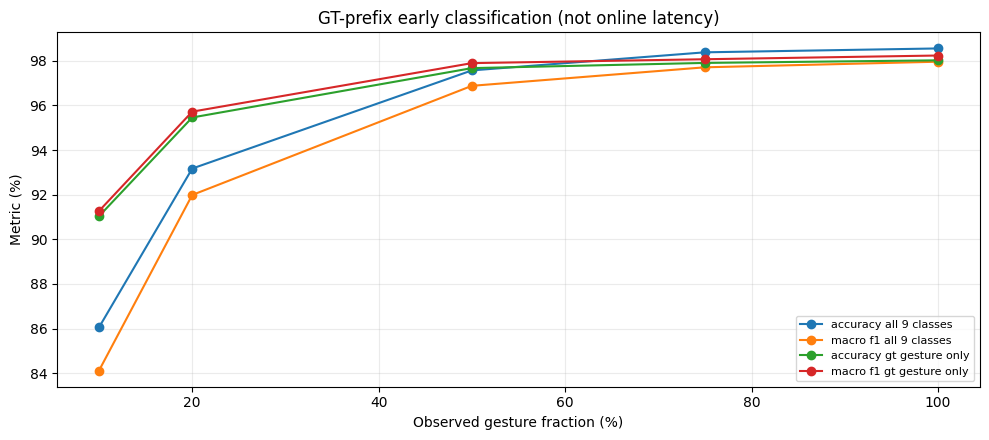

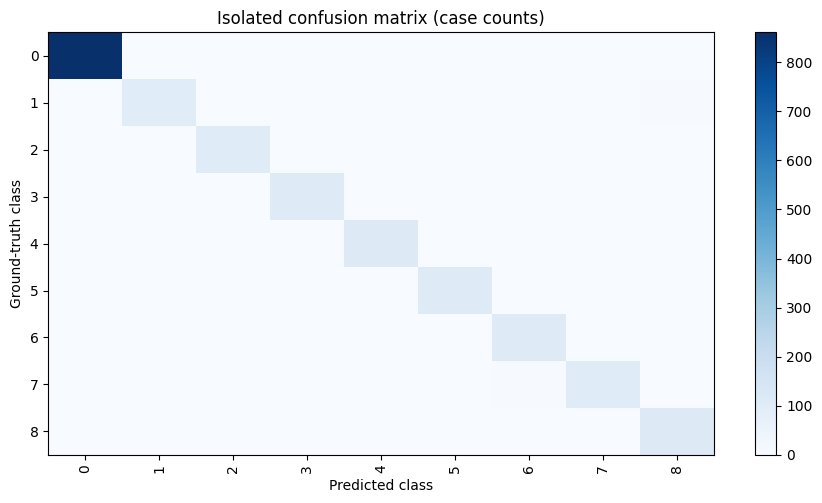

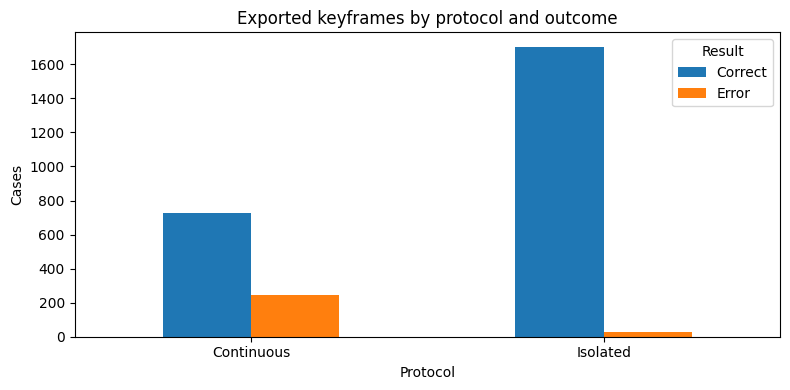

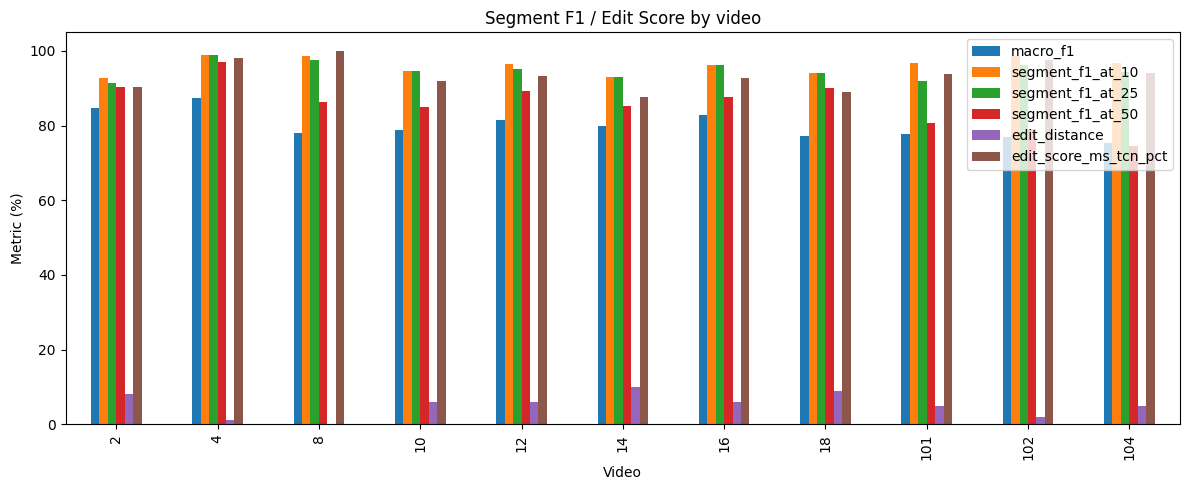

In [7]:
# Plot metrics derived from existing CSVs; no new VideoMamba inference.
import matplotlib.pyplot as plt

def csv_by_basename(filename):
    matches=[name for name in CSV_PATHS if Path(name).name==filename]
    return read_table(matches[0]) if len(matches)==1 else None

print('PLOTS FROM ATTACHED EVALUATION OUTPUT')
# Early Accuracy: annotation-defined prefixes, NOT online prediction latency.
early=csv_by_basename('early_accuracy_curve.csv')
if early is not None:
    xcol=next((c for c in ['observation_ratio','observed_fraction','prefix_ratio'] if c in early),None)
    if xcol:
        ycols=[c for c in early if c!=xcol and ('accuracy' in c.lower() or 'macro_f1' in c.lower())
               and pd.api.types.is_numeric_dtype(early[c])]
        if ycols:
            fig,ax=plt.subplots(figsize=(10,4.5))
            for col in ycols:
                y=pd.to_numeric(early[col],errors='coerce')
                if y.max()<=1.1:y=y*100
                ax.plot(pd.to_numeric(early[xcol])*100,y,marker='o',label=col.replace('_',' '))
            ax.set(xlabel='Observed gesture fraction (%)',ylabel='Metric (%)',
                   title='GT-prefix early classification (not online latency)')
            ax.legend(fontsize=8);ax.grid(alpha=.25);plt.tight_layout();plt.show()
    else: print('The early-curve CSV uses an unrecognized x-axis; inspect it in the CSV browser.')
else: print('No early_accuracy_curve.csv found.')

if {'gt_idx','pred_idx'}.issubset(iso_data.columns):
    truth=iso_data['gt_idx'].astype(int);pred=iso_data['pred_idx'].astype(int)
    confusion=pd.crosstab(truth,pred).reindex(index=range(len(CLASS_CODES)),columns=range(len(CLASS_CODES)),fill_value=0)
    fig,ax=plt.subplots(figsize=(max(9,len(CLASS_CODES)*.7),max(5,len(CLASS_CODES)*.57)))
    view=ax.imshow(confusion.to_numpy(),cmap='Blues',aspect='auto')
    ax.set_xticks(range(len(CLASS_CODES)),labels=CLASS_CODES,rotation=90)
    ax.set_yticks(range(len(CLASS_CODES)),labels=CLASS_CODES)
    ax.set(xlabel='Predicted class',ylabel='Ground-truth class',title='Isolated confusion matrix (case counts)')
    fig.colorbar(view,ax=ax);plt.tight_layout();plt.show()

counts=pd.crosstab(IMAGE_INDEX['Protocol'],IMAGE_INDEX['Result'])
if len(counts):
    ax=counts.plot(kind='bar',figsize=(8,4),rot=0,title='Exported keyframes by protocol and outcome')
    ax.set(xlabel='Protocol',ylabel='Cases');plt.tight_layout();plt.show()

by_video=csv_by_basename('continuous_raw_segment_metrics_per_video.csv')
if by_video is not None and len(by_video):
    cols=[c for c in by_video if 'f1' in c.lower() or 'edit' in c.lower()]
    xcol=next((c for c in ['video_id','video','video_key'] if c in by_video),None)
    if cols and xcol:
        part=by_video[[xcol]+cols].copy().set_index(xcol)
        for col in cols:
            part[col]=pd.to_numeric(part[col],errors='coerce')
            if part[col].max()<=1.1:part[col]*=100
        ax=part.plot(kind='bar',figsize=(12,5),title='Segment F1 / Edit Score by video')
        ax.set(xlabel='Video',ylabel='Metric (%)');plt.tight_layout();plt.show()

## 8. Other figures, logs, notes, artifacts and cache files

In [8]:
# Examine all remaining figures, logs, notes, and cache file metadata.
from IPython.display import Image as NotebookImage
other_images=[Path(x) for x in INVENTORY.loc[INVENTORY['Type']=='PNG figure','Absolute path']]
if not other_images: print('No separate PNG figures found; plots above were reconstructed from saved CSVs.')
for path in other_images:
    print('FIGURE:',path.relative_to(OUTPUT_ROOT))
    display(NotebookImage(filename=str(path),width=900))

text_types={'Text file','Log file','Markdown file','Configuration','TSV table','HTML report'}
text_files=INVENTORY[INVENTORY['Type'].isin(text_types)]
print('\nTEXT FILES / NOTES / LOGS / CONFIGURATION')
if text_files.empty:print('No additional text/configuration files in this Output.')
else:
    for filename in text_files['Absolute path']:
        p=Path(filename)
        try:
            if p.stat().st_size>2_000_000:
                print('Large text file (listed, not embedded):',p.relative_to(OUTPUT_ROOT))
                continue
            contents=p.read_text(encoding='utf-8',errors='replace')
            print('TEXT:',p.relative_to(OUTPUT_ROOT),f'({len(contents):,} characters)')
            display(HTML('<pre style="white-space:pre-wrap;max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
                         +html.escape(contents)+'</pre>'))
        except Exception as e:print('Unable to read text:',p.name,e)

print('\nRAW INFERENCE CACHE / DATA ARRAY / BINARY ARTIFACTS')
cache_types={'Raw inference cache','NumPy array','Parquet data','PDF report','SVG figure'}
cache_files=INVENTORY[INVENTORY['Type'].isin(cache_types)]
if len(cache_files):
    display(cache_files[['Type','Relative path','Size (KiB)']])
    print('Pickle files are intentionally NOT unpickled: deserialization can execute code. '
          'CSV and JSON are displayed above; raw caches are available for controlled offline analysis.')
else:print('No binary or cache files detected.')
print('\nNote: This viewer reads saved results only. It does not recompute predictions or metrics.')

No separate PNG figures found; plots above were reconstructed from saved CSVs.

TEXT FILES / NOTES / LOGS / CONFIGURATION
No additional text/configuration files in this Output.

RAW INFERENCE CACHE / DATA ARRAY / BINARY ARTIFACTS


,Type,Relative path,Size (KiB)
2732,Raw inference cache,continuous_raw_cache.pkl,974.7
2733,Raw inference cache,per_video_raw_cache/002_raw.pkl,155.0
2734,Raw inference cache,per_video_raw_cache/004_raw.pkl,62.6
2735,Raw inference cache,per_video_raw_cache/008_raw.pkl,84.2
2736,Raw inference cache,per_video_raw_cache/010_raw.pkl,76.5
2737,Raw inference cache,per_video_raw_cache/012_raw.pkl,91.3
2738,Raw inference cache,per_video_raw_cache/014_raw.pkl,96.1
2739,Raw inference cache,per_video_raw_cache/016_raw.pkl,95.2
2740,Raw inference cache,per_video_raw_cache/018_raw.pkl,83.5
2741,Raw inference cache,per_video_raw_cache/101_raw.pkl,84.1


Pickle files are intentionally NOT unpickled: deserialization can execute code. CSV and JSON are displayed above; raw caches are available for controlled offline analysis.

Note: This viewer reads saved results only. It does not recompute predictions or metrics.


## 9. Optional: embed ALL keyframe images into notebook cell output

In [9]:
# Optional: embed every single JPEG in notebook cell output.
# CAUTION: Thousands of embedded base64 images can make Kaggle or the browser unresponsive.
DISPLAY_ALL_IMAGES_INLINE = False
IMAGES_PER_BATCH = 12
if DISPLAY_ALL_IMAGES_INLINE:
    for protocol in ['Isolated','Continuous']:
        for status in ['Error','Correct']:
            total=len(filter_images(protocol,status))
            pages=math.ceil(total/IMAGES_PER_BATCH)
            print(f'EMBED ALL: {protocol} · {status} · {total} images')
            for page in range(1,pages+1):
                show_images(protocol,status,page,IMAGES_PER_BATCH)
else:
    print('All images are available in the paginated English gallery (Section 6).')
    print('Set DISPLAY_ALL_IMAGES_INLINE=True to embed every image in one notebook output cell.')

All images are available in the paginated English gallery (Section 6).
Set DISPLAY_ALL_IMAGES_INLINE=True to embed every image in one notebook output cell.
